In [1]:
!pip install shap scikit-learn pandas matplotlib -q
print("Libraries installed successfully!")


Libraries installed successfully!


In [2]:
import shap
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Load the California Housing dataset
california = fetch_california_housing(as_frame=True)
X = california.data
y = california.target

# Split into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (16512, 8)
Testing set shape: (4128, 8)


In [3]:
# Train a linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict and evaluate
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.4f}")
print(f"R² Score: {r2:.4f}")

Mean Squared Error: 0.5559
R² Score: 0.5758


ExactExplainer explainer: 4129it [00:29, 130.66it/s]                          


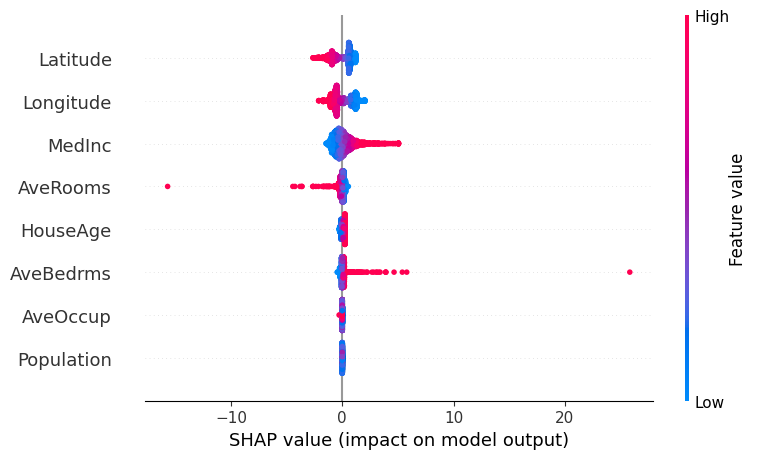

In [4]:
# Initialize SHAP explainer using the training data
explainer = shap.Explainer(model.predict, X_train)
shap_values = explainer(X_test)

# Generate and display the SHAP summary plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, show=True)

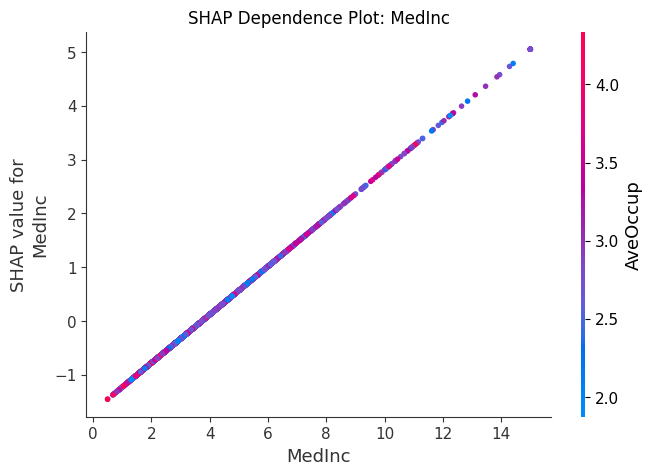

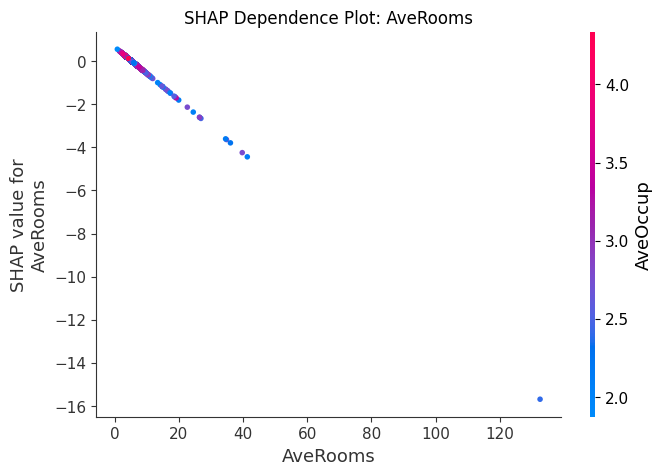

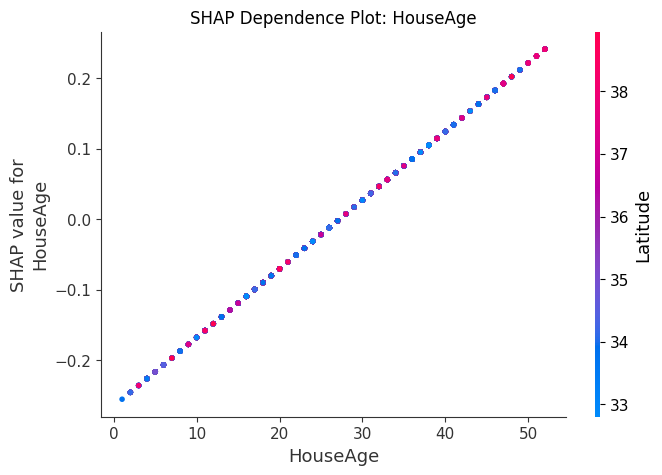

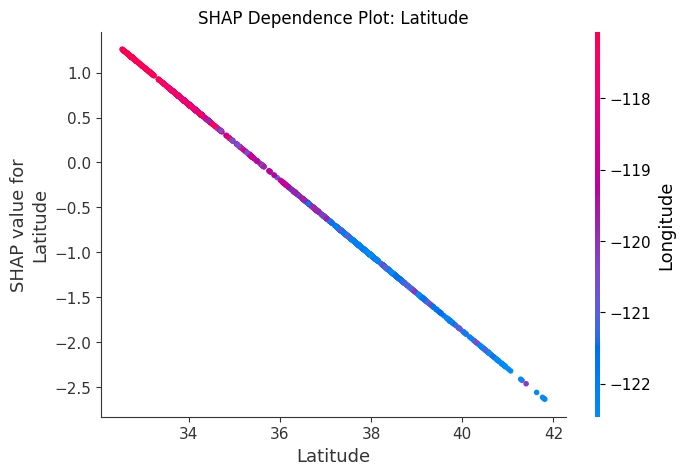

In [7]:
# Selected features for dependence analysis
selected_features = ['MedInc', 'AveRooms', 'HouseAge', 'Latitude']

for feature in selected_features:
    shap.dependence_plot(feature, shap_values.values, X_test, feature_names=X_test.columns, show=False)
    plt.title(f"SHAP Dependence Plot: {feature}")
    plt.savefig(f"shap_dependence_{feature}.png", bbox_inches='tight')
    plt.show()
    plt.close()

